In [1]:
from sklearn.metrics import classification_report,confusion_matrix
import numpy as np
from tensorflow.keras.models import load_model


best_model = load_model("../models/best_brainscan.keras")


X_test = np.load("../data/processed/X_test.npy")
y_test = np.load("../data/processed/y_test.npy")

y_pred_proba=best_model.predict(X_test)

y_pre=np.argmax(y_pred_proba,axis=1)


class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

print(classification_report(y_test,y_pre,target_names=class_names))

print(confusion_matrix(y_test,y_pre))

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 193ms/step
              precision    recall  f1-score   support

      glioma       0.92      0.91      0.92       243
  meningioma       0.88      0.88      0.88       245
     notumor       0.97      0.97      0.97       260
   pituitary       0.97      0.98      0.97       261

    accuracy                           0.94      1009
   macro avg       0.94      0.94      0.94      1009
weighted avg       0.94      0.94      0.94      1009

[[221  22   0   0]
 [ 16 216   8   5]
 [  0   4 253   3]
 [  2   4   0 255]]


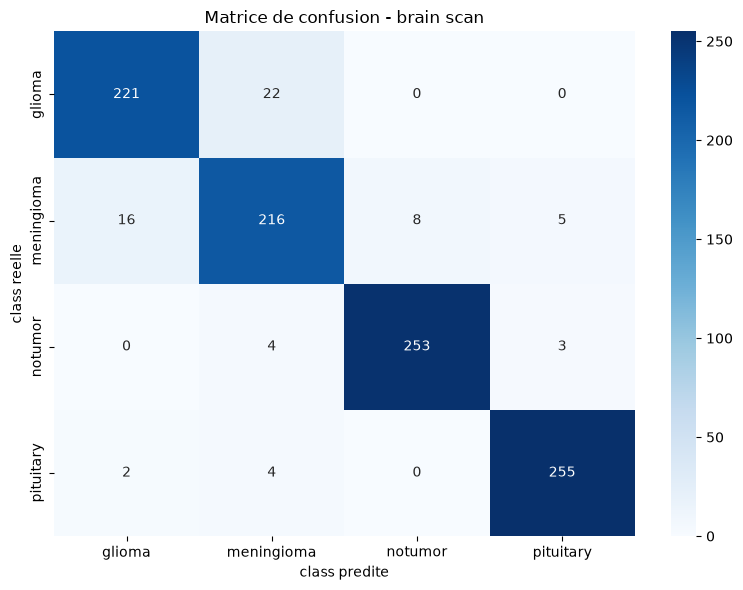

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test,y_pre)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("class predite")
plt.ylabel("class reelle")
plt.title("Matrice de confusion - brain scan") 
plt.tight_layout()
plt.show()

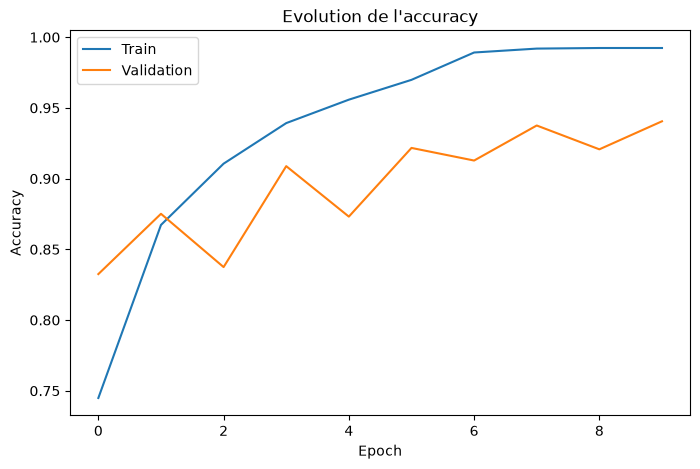

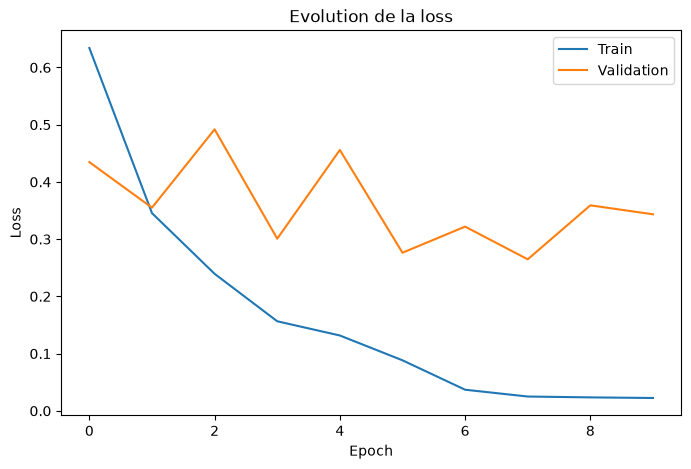

In [3]:
import matplotlib.pyplot as plt
import pickle

with open("../data/processed/history.pkl","rb") as f:
    history=pickle.load(f)

# courbes de precision
plt.figure(figsize=(8, 5))
plt.plot(history["accuracy"], label="Train")
plt.plot(history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolution de l'accuracy")
plt.legend()
plt.show()

# courbes de perte
plt.figure(figsize=(8, 5))
plt.plot(history["loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Evolution de la loss")
plt.legend()
plt.show()

In [4]:
# save les resultat d'evaluation

report=classification_report(y_test,y_pre,target_names=class_names)

with open("../models/evaluation_report.txt", "w", encoding="utf-8") as f:
    f.write(report)
